(a) Model
    mu = 70, phi1 = 0.3000, theta1 = 0.3333
    y_t - 70 = 0.3000(y_t-1 - 70) + e_t - 0.3333 e_t-1

(b) Conditions
    |phi1| = 0.3000 < 1 -> stationary: True
    |theta1| = 0.3333 < 1 -> invertible: True

(c) Moments
    gamma0 = 4.0049
    gamma1 = -0.1319
    rho1 = -0.0329
    rho2 = -0.0099
    rho3 = -0.0030

(d) Behaviour
    Geometric decay at rate phi1 = 0.3000 from lag 1; half-life ~ 0.58 lags
    ACF shape: monotone decay, rho1 = -0.0329


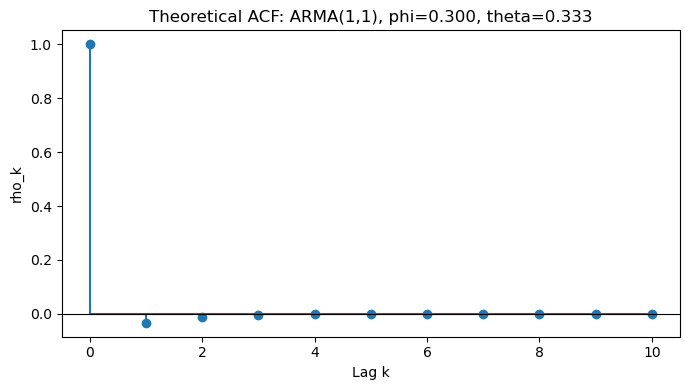

In [7]:
import math
import matplotlib.pyplot as plt

A, B, C = 3, 5, 2   # Student A
D, E, F = 4, 1, 6   # Student B (E, F unused in the model)
SIGMA2 = 4.0

# (a) Model construction
mu = 10 * (A + D)
phi = A / (A + B + 2)
theta = C / (C + 4)
print("(a) Model")
print(f"    mu = {mu}, phi1 = {phi:.4f}, theta1 = {theta:.4f}")
print(f"    y_t - {mu} = {phi:.4f}(y_t-1 - {mu}) + e_t - {theta:.4f} e_t-1\n")

# (b) Stationarity / invertibility
stationary = abs(phi) < 1
invertible = abs(theta) < 1
print("(b) Conditions")
print(f"    |phi1| = {abs(phi):.4f} < 1 -> stationary: {stationary}")
print(f"    |theta1| = {abs(theta):.4f} < 1 -> invertible: {invertible}\n")

# (c) Autocovariances / autocorrelations
g0 = SIGMA2 * (1 + theta**2 - 2 * phi * theta) / (1 - phi**2)
g1 = phi * g0 - theta * SIGMA2
gamma = [g0, g1]
for k in range(2, 11):
    gamma.append(phi * gamma[-1])
rho = [g / g0 for g in gamma]

print("(c) Moments")
print(f"    gamma0 = {g0:.4f}")
print(f"    gamma1 = {g1:.4f}")
for k in (1, 2, 3):
    print(f"    rho{k} = {rho[k]:.4f}")
print()

# (d) Behaviour
print("(d) Behaviour")
if 0 < phi < 1:
    half_life = math.log(0.5) / math.log(phi)
    print(f"    Geometric decay at rate phi1 = {phi:.4f} from lag 1; "
          f"half-life ~ {half_life:.2f} lags")
sign = "alternating" if phi < 0 else "monotone"
print(f"    ACF shape: {sign} decay, rho1 = {rho[1]:.4f}")

lags = list(range(0, 11))
plt.figure(figsize=(7, 4))
plt.stem(lags, rho[:11])
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("Lag k")
plt.ylabel("rho_k")
plt.title(f"Theoretical ACF: ARMA(1,1), phi={phi:.3f}, theta={theta:.3f}")
plt.tight_layout()
plt.show()

(a) Std of deviation from trend, by 60-month block
Series       Block 1   Block 2   Block 3   Ratio 3/1
Raw Y        13.6021   43.5782  162.3543       11.94
sqrt(Y)       0.4742    0.8269    1.7001        3.59
ln(Y)         0.0691    0.0661    0.0769        1.11
Ratio ~1 means constant variance; only ln(Y) achieves it.



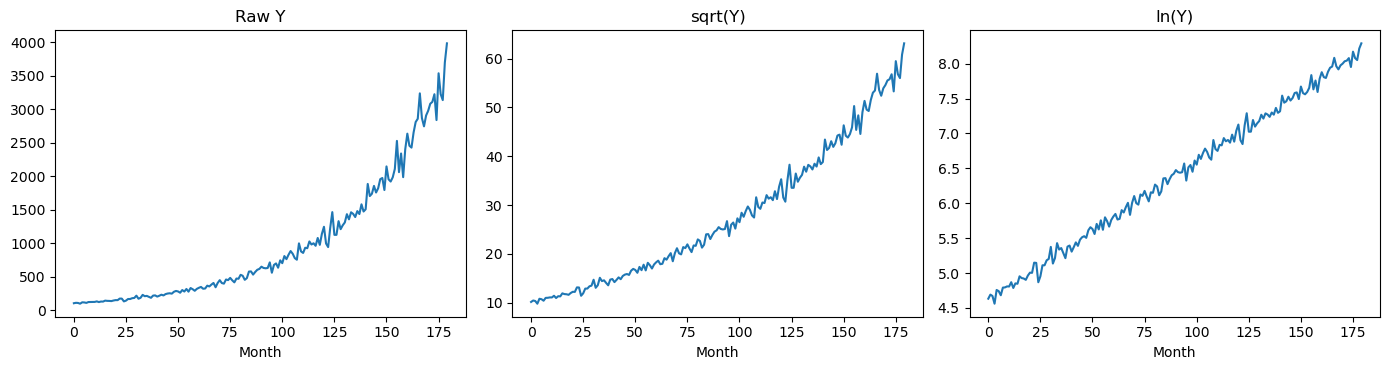

(b) ln(1+x) vs x
       x     ln(1+x)   abs error
     0.5    0.405465    0.094535
     0.2    0.182322    0.017678
     0.1    0.095310    0.004690
    0.05    0.048790    0.001210
    0.01    0.009950    0.000050
   0.001    0.001000    0.000000
Max |W_t - fractional change| on simulated Y: 0.04359

(c) (1 - B)(1 - B^12) = B**13 - B**12 - B + 1
    => ln(Y_t) - ln(Y_t-1) - ln(Y_t-12) + ln(Y_t-13)


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# ---------- (a) Log vs square-root variance stabilization ----------
rng = np.random.default_rng(1)
T = 180
t = np.arange(T)
trend = 100 * np.exp(0.02 * t)                 # exponential growth
Y = trend * np.exp(rng.normal(0, 0.08, T))     # multiplicative noise

transforms = {
    "Raw Y": Y,
    "sqrt(Y)": np.sqrt(Y),
    "ln(Y)": np.log(Y),
}
trend_t = {"Raw Y": trend, "sqrt(Y)": np.sqrt(trend), "ln(Y)": np.log(trend)}

print("(a) Std of deviation from trend, by 60-month block")
print(f"{'Series':<10}{'Block 1':>10}{'Block 2':>10}{'Block 3':>10}{'Ratio 3/1':>12}")
for name, z in transforms.items():
    dev = z - trend_t[name]
    s = [dev[i:i + 60].std() for i in (0, 60, 120)]
    print(f"{name:<10}{s[0]:>10.4f}{s[1]:>10.4f}{s[2]:>10.4f}{s[2] / s[0]:>12.2f}")
print("Ratio ~1 means constant variance; only ln(Y) achieves it.\n")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, z) in zip(axes, transforms.items()):
    ax.plot(t, z)
    ax.set_title(name)
    ax.set_xlabel("Month")
plt.tight_layout()
plt.show()

# ---------- (b) ln(1+x) ~ x numerical check ----------
print("(b) ln(1+x) vs x")
print(f"{'x':>8}{'ln(1+x)':>12}{'abs error':>12}")
for x in (0.5, 0.2, 0.1, 0.05, 0.01, 0.001):
    print(f"{x:>8}{np.log1p(x):>12.6f}{abs(np.log1p(x) - x):>12.6f}")

# Same check on the simulated series
W = np.diff(np.log(Y))
frac = np.diff(Y) / Y[:-1]
print(f"Max |W_t - fractional change| on simulated Y: {np.max(np.abs(W - frac)):.5f}\n")

# ---------- (c) Seasonal differencing expansion ----------
B = sp.symbols("B")
poly = sp.expand((1 - B) * (1 - B**12))
print("(c) (1 - B)(1 - B^12) =", poly)

terms = {int(m.as_coeff_exponent(B)[1]): m.as_coeff_exponent(B)[0]
         for m in poly.as_ordered_terms()}
expr = " ".join(
    f"{'+' if c > 0 else '-'} ln(Y_t{'' if k == 0 else f'-{k}'})"
    for k, c in sorted(terms.items())
).lstrip("+ ")
print("    =>", expr)

In [9]:
import numpy as np
from scipy import stats

# ---------- Given output ----------
N, k = 30, 3
p = k + 1
SSR, SSE, SST = 12450.0, 1300.0, 13750.0
dfR, dfE = k, N - k - 1
vif = {"X1 Floor Area": 8.42, "X2 Operating Hours": 1.15, "X3 Peak Load": 8.18}
se = {"X1 Floor Area": 0.45, "X2 Operating Hours": 0.38, "X3 Peak Load": 0.22}
d = 0.82
dL, dU = 1.21, 1.65
h14, e14, r14, D14 = 0.28, 18.5, 2.85, 0.79

# ---------- (a) Overall F test ----------
MSR, MSE = SSR / dfR, SSE / dfE
F = MSR / MSE
Fcrit = stats.f.ppf(0.95, dfR, dfE)
pF = stats.f.sf(F, dfR, dfE)
R2 = SSR / SST
adjR2 = 1 - (SSE / dfE) / (SST / (N - 1))
print("(a) Overall significance")
print("    H0: b1 = b2 = b3 = 0   vs   H1: at least one bj != 0")
print(f"    MSR = {MSR:.1f}, MSE = {MSE:.1f}, F = {F:.2f}")
print(f"    F crit (0.05; {dfR},{dfE}) = {Fcrit:.3f}, p-value = {pF:.2e}")
print(f"    Decision: {'Reject' if F > Fcrit else 'Fail to reject'} H0")
print(f"    R2 = {R2:.4f}, adj R2 = {adjR2:.4f} "
      f"-> {R2 * 100:.2f}% of variation in demand explained\n")

# ---------- (b) Multicollinearity ----------
print("(b) Multicollinearity")
print(f"    {'Predictor':<20}{'VIF':>6}{'R2_j':>8}{'SE x sqrt(VIF)':>16}")
for name in vif:
    print(f"    {name:<20}{vif[name]:>6.2f}{1 - 1 / vif[name]:>8.3f}"
          f"{np.sqrt(vif[name]):>16.2f}")
worst = sorted(vif, key=vif.get, reverse=True)[:2]
print(f"    Collinear pair: {worst[0]} and {worst[1]}")
print("    Var(b_j) = s2 / [Sxx_j (1 - R2_j)] = VIF_j x (variance without collinearity)\n")

# ---------- (c) Durbin-Watson ----------
print("(c) Durbin-Watson")
print("    H0: rho = 0   vs   H1: rho > 0")
print(f"    d = {d}, dL = {dL}, dU = {dU}")
if d < dL:
    verdict = "d < dL -> reject H0: positive autocorrelation"
elif d > dU:
    verdict = "d > dU -> fail to reject H0"
else:
    verdict = "dL <= d <= dU -> inconclusive"
print(f"    {verdict}\n")

# ---------- (d) Cochrane-Orcutt ----------
phi = 1 - d / 2
print("(d) Cochrane-Orcutt")
print(f"    phi_hat = 1 - d/2 = {phi:.2f}")
print(f"    Y*_t  = Y_t  - {phi:.2f} Y_(t-1)")
print(f"    X1*_t = X1_t - {phi:.2f} X1_(t-1)   (same for X2, X3)")
print(f"    Intercept becomes b0(1 - phi) = 142.50 x {1 - phi:.2f} = {142.5 * (1 - phi):.3f}; "
      f"recover b0 = b0*/(1 - phi)")
print("    Residual: e*_t = e_t - phi e_(t-1) = u_t (white noise) -> OLS SEs valid")


def cochrane_orcutt(y, X, tol=1e-6, max_iter=50):
    """Iterative Cochrane-Orcutt. X excludes the intercept column."""
    Xc = np.column_stack([np.ones(len(y)), X])
    b = np.linalg.lstsq(Xc, y, rcond=None)[0]
    rho = 0.0
    for _ in range(max_iter):
        e = y - Xc @ b
        rho_new = (e[1:] @ e[:-1]) / (e[:-1] @ e[:-1])
        ys = y[1:] - rho_new * y[:-1]
        Xs = Xc[1:] - rho_new * Xc[:-1]
        bs = np.linalg.lstsq(Xs, ys, rcond=None)[0]
        b = bs  # coefficient on the transformed constant column (1 - rho) is b0 itself
        if abs(rho_new - rho) < tol:
            break
        rho = rho_new
    return b, rho_new


def dw(e):
    return np.sum(np.diff(e) ** 2) / np.sum(e ** 2)


# Demo on simulated data with AR(1) errors (the real data are not provided)
rng = np.random.default_rng(0)
n = 60
X = rng.normal(size=(n, 2))
u = rng.normal(size=n)
err = np.zeros(n)
for i in range(1, n):
    err[i] = 0.6 * err[i - 1] + u[i]
y = 5 + 2 * X[:, 0] + 1 * X[:, 1] + err
Xc = np.column_stack([np.ones(n), X])
b_ols = np.linalg.lstsq(Xc, y, rcond=None)[0]
b_co, rho_hat = cochrane_orcutt(y, X)
e_ols = y - Xc @ b_ols
e_co = (y[1:] - rho_hat * y[:-1]) - (Xc[1:] - rho_hat * Xc[:-1]) @ b_co
print(f"    Simulated demo: DW before = {dw(e_ols):.2f}, after CO = {dw(e_co):.2f}, "
      f"rho_hat = {rho_hat:.2f}\n")

# ---------- (e) Outlier / leverage / influence ----------
s = np.sqrt(MSE)
r_check = e14 / (s * np.sqrt(1 - h14))
D_check = r14 ** 2 / p * h14 / (1 - h14)
print("(e) Observation 14")
print(f"    Leverage:  h = {h14} vs 2p/N = {2 * p / N:.3f} -> "
      f"{'HIGH leverage' if h14 > 2 * p / N else 'not high'}")
print(f"    Studentized residual: |r| = {abs(r14)} -> "
      f"{'outlier (|r| > 2)' if abs(r14) > 2 else 'not an outlier'}"
      f"{'' if abs(r14) > 3 else ' (below the stricter cutoff of 3)'}")
print(f"    Cook's D = {D14}: > 4/N = {4 / N:.3f}: {D14 > 4 / N}; "
      f"> 0.5: {D14 > 0.5}; > 1: {D14 > 1}")
print(f"    Check: D = r^2/p * h/(1-h) = {D_check:.2f}")
print(f"    Check: e/(s sqrt(1-h)) = {r_check:.2f}  (given r14 = {r14})")
print("    Classification: high-leverage outlier and influential point")

(a) Overall significance
    H0: b1 = b2 = b3 = 0   vs   H1: at least one bj != 0
    MSR = 4150.0, MSE = 50.0, F = 83.00
    F crit (0.05; 3,26) = 2.975, p-value = 1.93e-13
    Decision: Reject H0
    R2 = 0.9055, adj R2 = 0.8945 -> 90.55% of variation in demand explained

(b) Multicollinearity
    Predictor              VIF    R2_j  SE x sqrt(VIF)
    X1 Floor Area         8.42   0.881            2.90
    X2 Operating Hours    1.15   0.130            1.07
    X3 Peak Load          8.18   0.878            2.86
    Collinear pair: X1 Floor Area and X3 Peak Load
    Var(b_j) = s2 / [Sxx_j (1 - R2_j)] = VIF_j x (variance without collinearity)

(c) Durbin-Watson
    H0: rho = 0   vs   H1: rho > 0
    d = 0.82, dL = 1.21, dU = 1.65
    d < dL -> reject H0: positive autocorrelation

(d) Cochrane-Orcutt
    phi_hat = 1 - d/2 = 0.59
    Y*_t  = Y_t  - 0.59 Y_(t-1)
    X1*_t = X1_t - 0.59 X1_(t-1)   (same for X2, X3)
    Intercept becomes b0(1 - phi) = 142.50 x 0.41 = 58.425; recover b0 = b0*/

95% limits: +/- 0.183

(a) Stationarity
    Raw ACF: all 7/7 lags significant, slow near-linear decay (0.912 -> 0.558 by lag 6)
    Raw PACF: spike at lag 1 = 0.912 (~1, unit-root signature), then ~0
    Differenced ACF: only lag 1 significant (1/7), others within limits
    -> raw series non-stationary; d = 1 achieves stationarity
    Explanation: a stationary series has an ACF that dies out quickly. The raw ACF
    decays slowly and linearly because shocks never fade (a unit root), and the PACF
    lag-1 value near 1 confirms it. First differencing removes the stochastic trend,
    so the differenced ACF drops inside the limits after lag 1, as expected for a
    stationary series.

(b) Identification of W_t
    Significant ACF lags:  [1]  -> cuts off after lag 1
    Significant PACF lags: [1]  -> lag 2 value -0.121 is inside the limit; values taper off
    ACF cutoff at q = 1 + PACF tailing off -> MA(1) on W_t
    Tentative model: ARIMA(0, 1, 1)
    Moment estimate: r1 = -theta/(1+th

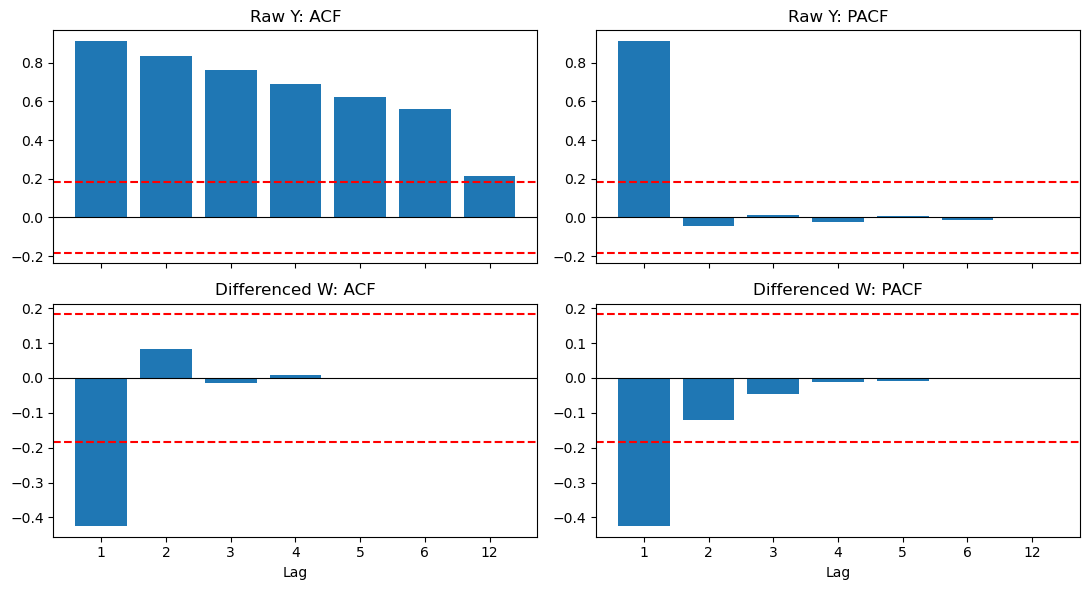

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

N = 120
lags = [1, 2, 3, 4, 5, 6, 12]
raw_acf = [0.912, 0.835, 0.761, 0.690, 0.622, 0.558, 0.215]
raw_pacf = [0.912, -0.042, 0.015, -0.021, 0.009, -0.011, 0.002]
dif_acf = [-0.425, 0.082, -0.015, 0.008, -0.002, 0.001, 0.000]
dif_pacf = [-0.425, -0.121, -0.045, -0.012, -0.008, -0.002, 0.001]
limit = 2 / np.sqrt(N)

# ---------- (a) Stationarity ----------
print(f"95% limits: +/- {limit:.3f}\n")
print("(a) Stationarity")
print(f"    Raw ACF: all {sum(abs(r) > limit for r in raw_acf)}/{len(raw_acf)} lags significant, "
      f"slow near-linear decay (0.912 -> 0.558 by lag 6)")
print("    Raw PACF: spike at lag 1 = 0.912 (~1, unit-root signature), then ~0")
print(f"    Differenced ACF: only lag 1 significant "
      f"({sum(abs(r) > limit for r in dif_acf)}/{len(dif_acf)}), others within limits")
print("    -> raw series non-stationary; d = 1 achieves stationarity")
print("    Explanation: a stationary series has an ACF that dies out quickly. The raw ACF")
print("    decays slowly and linearly because shocks never fade (a unit root), and the PACF")
print("    lag-1 value near 1 confirms it. First differencing removes the stochastic trend,")
print("    so the differenced ACF drops inside the limits after lag 1, as expected for a")
print("    stationary series.\n")

# ---------- (b) Order identification ----------
sig_acf = [l for l, r in zip(lags, dif_acf) if abs(r) > limit]
sig_pacf = [l for l, r in zip(lags, dif_pacf) if abs(r) > limit]
print("(b) Identification of W_t")
print(f"    Significant ACF lags:  {sig_acf}  -> cuts off after lag 1")
print(f"    Significant PACF lags: {sig_pacf}  -> lag 2 value {dif_pacf[1]} is inside the limit; "
      "values taper off")
r1 = dif_acf[0]
theta = (1 - np.sqrt(1 - 4 * r1**2)) / (2 * abs(r1))
print("    ACF cutoff at q = 1 + PACF tailing off -> MA(1) on W_t")
print("    Tentative model: ARIMA(0, 1, 1)")
print(f"    Moment estimate: r1 = -theta/(1+theta^2) -> theta ~ {theta:.3f}")
print("    Explanation (Box-Jenkins rules): MA(q) has an ACF that cuts off after lag q and a")
print("    PACF that tails off; AR(p) is the reverse. Here the ACF cuts off after lag 1 and")
print("    the PACF tails off, so q = 1, p = 0. Differencing once gives d = 1, hence")
print("    ARIMA(0,1,1). The negative r1 means a positive theta.\n")

# ---------- (c) Ljung-Box ----------
K = 3
r = [-0.425, 0.082, -0.015]
terms = [rk**2 / (N - k) for k, rk in enumerate(r, start=1)]
Q = N * (N + 2) * sum(terms)
crit = stats.chi2.ppf(0.95, K)
pval = stats.chi2.sf(Q, K)
print(f"(c) Ljung-Box, K = {K}")
for k, (rk, t) in enumerate(zip(r, terms), start=1):
    print(f"    lag {k}: r^2/(N-k) = {rk**2:.6f}/{N - k} = {t:.6f}")
print(f"    Q_LB = {N} x {N + 2} x {sum(terms):.6f} = {Q:.2f}")
print(f"    chi2 crit (0.05, {K}) = {crit:.2f}, p-value = {pval:.2e}")
print(f"    Q {'>' if Q > crit else '<='} crit -> "
      f"{'significant autocorrelation remains in W_t' if Q > crit else 'no significant autocorrelation'}")
print("    Explanation: H0 says the first K autocorrelations are all zero. Q exceeds the")
print("    critical value, so reject H0: W_t is not white noise. The autocorrelation found")
print("    is the lag-1 MA structure (r1 = -0.425), which the ARIMA(0,1,1) model is meant to")
print("    capture. To check the fitted model, run Ljung-Box on its residuals with")
print("    K - 1 degrees of freedom (K minus the number of fitted ARMA parameters).")

# ---------- Plots ----------
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
data = [
    (raw_acf, "Raw Y: ACF"), (raw_pacf, "Raw Y: PACF"),
    (dif_acf, "Differenced W: ACF"), (dif_pacf, "Differenced W: PACF"),
]
for ax, (vals, title) in zip(axes.flat, data):
    ax.bar(range(len(lags)), vals)
    ax.axhline(limit, color="r", ls="--")
    ax.axhline(-limit, color="r", ls="--")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(lags)))
    ax.set_xticklabels(lags)
    ax.set_title(title)
for ax in axes[1]:
    ax.set_xlabel("Lag")
plt.tight_layout()
plt.show()

PART III: APPLIED FORECASTING, EXPONENTIAL SMOOTHING & PERFORMANCE MONITORING

TASK 3.1: EXPONENTIAL SMOOTHING VS. ARIMA EQUIVALENCE

(a) SES update and multi-step forecasts
Forecast error: e_50 = y_50 - yhat_50|49 = 456.00 - 420.00 = 36.00 units
Updated level: yhat_51|50 = yhat_50|49 + alpha*e_50
             = 420.00 + 0.25(36.00) = 429.00 units
Forecast h=1 week: 429.00 units
Forecast h=2 weeks: 429.00 units
Forecast h=5 weeks: 429.00 units
Interpretation: SES produces the same point forecast for all future horizons,
because the method has no separate trend or seasonal component.

(b) ARIMA(0,1,1) equivalence
theta = 1 - alpha = 1 - 0.25 = 0.75
ARIMA difference equation: y_t = y_(t-1) + e_t - theta*e_(t-1)
Using the one-step forecast error e_t = y_t - yhat_t|t-1,
yhat_(t+1)|t = y_t - theta*e_t
               = y_t - 0.75e_t
               = y_t - (1 - alpha)e_t
               = y_t - e_t + alpha*e_t
               = yhat_t|t-1 + alpha*e_t
This is exactly the SES error-correction upd

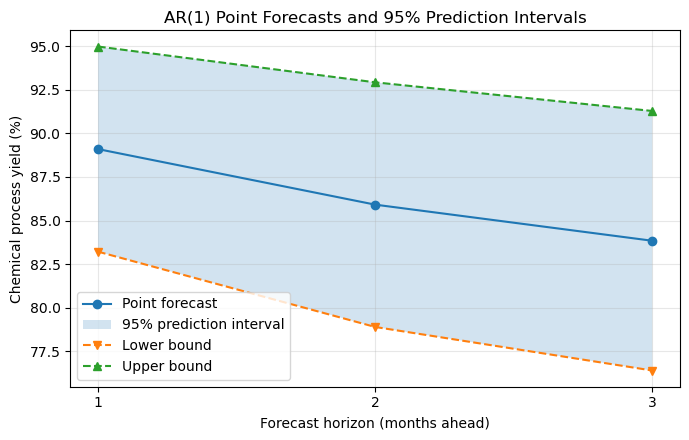


(d) Asymptotic variance
lim Var(e_h) = sigma_e^2 / (1 - phi^2) = 9 / (1 - 0.65^2) = 15.5844
Interpretation: For this stationary AR(1) process, the forecast error variance
approaches a finite limit, so prediction intervals remain bounded as the horizon grows.
For a non-stationary ARIMA(p,1,q) process, uncertainty from the accumulated
differences grows with the forecast horizon, so prediction intervals expand.

------------------------------------------------------------------------
TASK 3.3: FORECAST ERROR ACCURACY AND TRACKING SIGNAL MONITORING

(a) Error metric calculations
Sum of errors = 40.50
Mean Error (ME) = sum(e_t)/n = 40.50/10 = 4.05
Mean Absolute Deviation (MAD) = sum(|e_t|)/n = 44.50/10 = 4.45
Mean Squared Error (MSE) = sum(e_t^2)/n = 217.75/10 = 21.775

(b) Bias evaluation
ME is positive (4.05), so actual demand tends to exceed forecasts.
The model is systematically under-forecasting demand.

(c) Tracking signal
C_10 = sum(e_t) = 40.50
TS_10 = C_10 / MAD = 40.50 / 4.45 = 9

In [11]:
print("=" * 72)
print("PART III: APPLIED FORECASTING, EXPONENTIAL SMOOTHING & PERFORMANCE MONITORING")
print("=" * 72)

# ---------------------------------------------------------------------
# TASK 3.1: Exponential Smoothing vs. ARIMA Equivalence
# ---------------------------------------------------------------------
print("\nTASK 3.1: EXPONENTIAL SMOOTHING VS. ARIMA EQUIVALENCE")

alpha = 0.25
forecast_50 = 420.0
actual_50 = 456.0

# (a) SES update and multi-step forecasts
error_50 = actual_50 - forecast_50
forecast_51 = forecast_50 + alpha * error_50

print("\n(a) SES update and multi-step forecasts")
print(f"Forecast error: e_50 = y_50 - yhat_50|49 = {actual_50:.2f} - {forecast_50:.2f} = {error_50:.2f} units")
print(f"Updated level: yhat_51|50 = yhat_50|49 + alpha*e_50")
print(f"             = {forecast_50:.2f} + {alpha:.2f}({error_50:.2f}) = {forecast_51:.2f} units")
print(f"Forecast h=1 week: {forecast_51:.2f} units")
print(f"Forecast h=2 weeks: {forecast_51:.2f} units")
print(f"Forecast h=5 weeks: {forecast_51:.2f} units")
print("Interpretation: SES produces the same point forecast for all future horizons,")
print("because the method has no separate trend or seasonal component.")

# (b) ARIMA(0,1,1) equivalence
theta = 1 - alpha
print("\n(b) ARIMA(0,1,1) equivalence")
print(f"theta = 1 - alpha = 1 - {alpha:.2f} = {theta:.2f}")
print("ARIMA difference equation: y_t = y_(t-1) + e_t - theta*e_(t-1)")
print("Using the one-step forecast error e_t = y_t - yhat_t|t-1,")
print("yhat_(t+1)|t = y_t - theta*e_t")
print(f"               = y_t - {theta:.2f}e_t")
print("               = y_t - (1 - alpha)e_t")
print("               = y_t - e_t + alpha*e_t")
print("               = yhat_t|t-1 + alpha*e_t")
print("This is exactly the SES error-correction updating equation.")


# ---------------------------------------------------------------------
# TASK 3.2: MMSE Forecast Intervals and Horizon Expansion
# ---------------------------------------------------------------------
print("\n" + "-" * 72)
print("TASK 3.2: MMSE FORECAST INTERVALS AND HORIZON EXPANSION")

mu = 80.0
phi = 0.65
sigma2 = 9.0
y_T = 94.0
horizons = [1, 2, 3, 10]

# (a) Point forecasts
forecasts = {}
print("\n(a) Point forecasts")
for h in horizons:
    forecasts[h] = mu + (phi ** h) * (y_T - mu)
    print(f"h={h:2d}: yhat_(100+{h})|100 = 80 + (0.65)^{h}(94 - 80) = {forecasts[h]:.4f}%")

# (b) Forecast error variances for h = 1, 2, 3
variances = {}
print("\n(b) Forecast error variances")
for h in [1, 2, 3]:
    variance = sigma2 * sum(phi ** (2 * j) for j in range(h))
    variances[h] = variance
    print(f"h={h}: Var(e_{h}) = 9 * sum((0.65)^(2j), j=0,...,{h-1}) = {variance:.4f}")

# (c) 95% prediction intervals
print("\n(c) 95% prediction intervals")
intervals = {}
for h in [1, 2, 3]:
    se = np.sqrt(variances[h])
    lower = forecasts[h] - 1.96 * se
    upper = forecasts[h] + 1.96 * se
    intervals[h] = (lower, upper)
    print(f"h={h}: {forecasts[h]:.4f} +/- 1.96*sqrt({variances[h]:.4f})")
    print(f"     95% PI = ({lower:.4f}%, {upper:.4f}%)")

# Visualize forecast intervals
hs = np.array([1, 2, 3])
point_values = np.array([forecasts[h] for h in hs])
lower_values = np.array([intervals[h][0] for h in hs])
upper_values = np.array([intervals[h][1] for h in hs])

plt.figure(figsize=(7, 4.5))
plt.plot(hs, point_values, marker="o", label="Point forecast")
plt.fill_between(hs, lower_values, upper_values, alpha=0.2, label="95% prediction interval")
plt.plot(hs, lower_values, marker="v", linestyle="--", label="Lower bound")
plt.plot(hs, upper_values, marker="^", linestyle="--", label="Upper bound")
plt.xticks(hs)
plt.xlabel("Forecast horizon (months ahead)")
plt.ylabel("Chemical process yield (%)")
plt.title("AR(1) Point Forecasts and 95% Prediction Intervals")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# (d) Asymptotic forecast error variance
asymptotic_variance = sigma2 / (1 - phi ** 2)
print("\n(d) Asymptotic variance")
print(f"lim Var(e_h) = sigma_e^2 / (1 - phi^2) = 9 / (1 - 0.65^2) = {asymptotic_variance:.4f}")
print("Interpretation: For this stationary AR(1) process, the forecast error variance")
print("approaches a finite limit, so prediction intervals remain bounded as the horizon grows.")
print("For a non-stationary ARIMA(p,1,q) process, uncertainty from the accumulated")
print("differences grows with the forecast horizon, so prediction intervals expand.")


# ---------------------------------------------------------------------
# TASK 3.3: Forecast Error Accuracy and Tracking Signal Monitoring
# ---------------------------------------------------------------------
print("\n" + "-" * 72)
print("TASK 3.3: FORECAST ERROR ACCURACY AND TRACKING SIGNAL MONITORING")

errors = np.array([4.0, -2.0, 3.5, 5.0, 4.5, 6.0, 3.0, 5.5, 4.0, 7.0])

# (a) Error metrics
ME = np.mean(errors)
MAD = np.mean(np.abs(errors))
MSE = np.mean(errors ** 2)
cumulative_error = np.sum(errors)
tracking_signal = cumulative_error / MAD

print("\n(a) Error metric calculations")
print(f"Sum of errors = {cumulative_error:.2f}")
print(f"Mean Error (ME) = sum(e_t)/n = {cumulative_error:.2f}/10 = {ME:.2f}")
print(f"Mean Absolute Deviation (MAD) = sum(|e_t|)/n = {np.sum(np.abs(errors)):.2f}/10 = {MAD:.2f}")
print(f"Mean Squared Error (MSE) = sum(e_t^2)/n = {np.sum(errors**2):.2f}/10 = {MSE:.3f}")

# (b) Bias evaluation
print("\n(b) Bias evaluation")
if ME > 0:
    print(f"ME is positive ({ME:.2f}), so actual demand tends to exceed forecasts.")
    print("The model is systematically under-forecasting demand.")
elif ME < 0:
    print(f"ME is negative ({ME:.2f}), so forecasts tend to exceed actual demand.")
    print("The model is systematically over-forecasting demand.")
else:
    print("ME is zero, indicating no net bias over these observations.")

# (c) Tracking signal
print("\n(c) Tracking signal")
print(f"C_10 = sum(e_t) = {cumulative_error:.2f}")
print(f"TS_10 = C_10 / MAD = {cumulative_error:.2f} / {MAD:.2f} = {tracking_signal:.3f}")
print("Control limit: |TS| <= 4.0")
if abs(tracking_signal) > 4.0:
    print(f"Since |TS_10| = {abs(tracking_signal):.3f} > 4.0, the system is OUT OF CONTROL.")
    print("The positive tracking signal indicates persistent under-forecasting; model recalibration is required.")
else:
    print(f"Since |TS_10| = {abs(tracking_signal):.3f} <= 4.0, the system is within the control limits.")
